In [37]:
import pandas
from tqdm.auto import tqdm
import requests
import glob

In [38]:
data = []

In [39]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.mlab import GaussianKDE
import matplotlib.patheffects as pe
import numpy as np

In [40]:
def str_to_seconds(time):
    com = str(time).replace(".", ":").split(":")
    try: 
        if len(com) == 3:
                seconds = int(com[2])+60*int(com[1])+3600*int(com[0])
        elif len(com) == 2:
            seconds = 60*int(com[0])+ int(com[1])
        else:
            seconds = -1
    except ValueError:
        seconds = -1
    return seconds

In [41]:
data = []
for race in glob.glob("/home/daniel/repositories/personal/scottish-hillrunners-results/races/Tinto/*.csv"):
    data.append(pandas.read_csv(race))
frames = pandas.concat(data)

In [42]:
frames['FinishTime']

0        30.50
1        31.35
2        32.41
3        32.54
4        33.18
        ...   
211    1:10:25
212    1:11:46
213    1:17:31
214    1:17:41
215    1:17:44
Name: FinishTime, Length: 6470, dtype: object

In [43]:
frames['Finish Time (seconds)'] = frames['FinishTime'].map(str_to_seconds)

In [44]:
frames['Finish Time (seconds)']/60

0      30.833333
1      31.583333
2      32.683333
3      32.900000
4      33.300000
         ...    
211    70.416667
212    71.766667
213    77.516667
214    77.683333
215    77.733333
Name: Finish Time (seconds), Length: 6470, dtype: float64

In [45]:
frames[frames['Finish Time (seconds)']>0].sort_values('Finish Time (seconds)', ascending=True)

,RunnerPosition,Surname,Firstname,Club,RunnerCategory,FinishTime,FinishPosition,Finish Time (seconds)
0,1,McLeod,Mark,Moorfoots,NaN,24.06,NaN,1446
1,2,Emsley,Nick,Arran,NaN,24.54,NaN,1494
2,3,Aitken,Martha,Carnethy,F,25.26,NaN,1526
3,4,Stokoe,Deborah,Westerlands,F,26.11,NaN,1571
4,5,Aitken,Evie,Carnethy,F,27.07,NaN,1627
...,...,...,...,...,...,...,...,...
230,231,Mickleburgh,Rebecca,Unattached,F,01:20:25,NaN,4825
127,128,Allan,Eileen,U/A,F,83:36,NaN,5016
99,100.0,Webb-Bowen,John,Edin West,SV,86:38,NaN,5198
155,NaN,Wilson,Abbie,Hartfell Hill Running Club,FS,01:28:03,156.0,5283


/tmp/ipykernel_813647/731734970.py:18: UserWarning: The figure layout has changed to tight
  f.tight_layout()


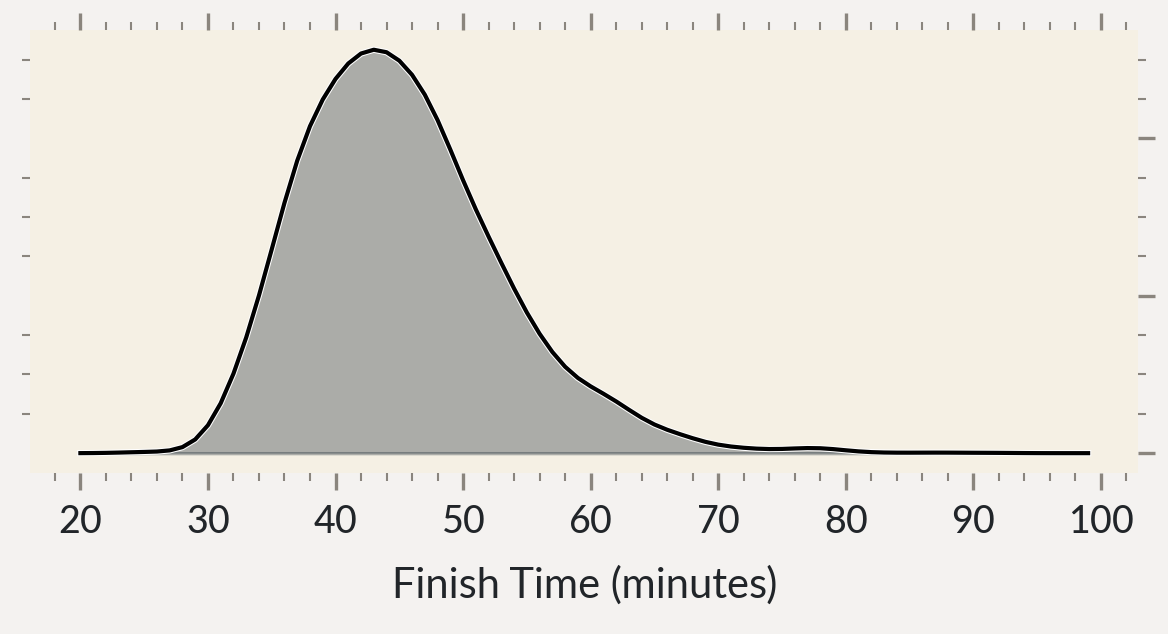

In [46]:
f, ax = plt.subplots(1,1, dpi=300, figsize=(4,2))
axis = range(20,100,1)

#ax.axvline(180)
#ax.axvline(240)
#ax.axvline(300)

ax.fill_between(axis, 100*GaussianKDE(frames['Finish Time (seconds)']/60)(axis), alpha=0.3, color = '#00111f')
ax.plot(axis, 100*GaussianKDE(frames['Finish Time (seconds)']/60)(axis), color="black", linewidth=1, path_effects=[pe.Stroke(linewidth=1.5, foreground='w'), pe.Normal()])
    
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set(yticklabels=[])
ax.tick_params(left=False)
ax.grid(False)
f.tight_layout()

ax.set_xlabel("Finish Time (minutes)")
f.savefig("tinto-finish-times.jpg")

In [47]:
frames['Finish Time (seconds)'].quantile(0.5)/60

np.float64(44.11666666666667)

In [48]:
frames['RunnerCategory'].unique()

array(['S', 'V', 'FS', 'SV', 'SSV', 'SSSV', 'VS', 'FV', 'FJ', 'FSV',
       'FDS', nan, 'J', 'F', 'M', 'M40', 'M50', 'M60', 'F40', 'F50',
       'M70', 'F60', 'M80', 'v', 'f', 'v50', 'v60', 'fv', 'f50', 'fv50',
       'M ', 'Vet', 'S/Vet', 'Jnr', 'U 15', 'S/L', 'L/S', 'Over60',
       'L/Vet',
       'Due to the exceptionly bad weather the following were not recorded at the finish :',
       'MV', 'MJ', 'F70', 'MS', 'V50', 'V60', 'V40'], dtype=object)

In [49]:
men = frames[frames['RunnerCategory'].apply(lambda x: str(x)[-1] in ("M", "S", "V", "O"))]
women = frames[frames['RunnerCategory'].apply(lambda x: str(x)[-1] in ("F", "f"))]
#nbinary = frames[frames['Category'].apply(lambda x: x[-1])=="N"]

/tmp/ipykernel_813647/4213764241.py:21: UserWarning: The figure layout has changed to tight
  f.tight_layout()


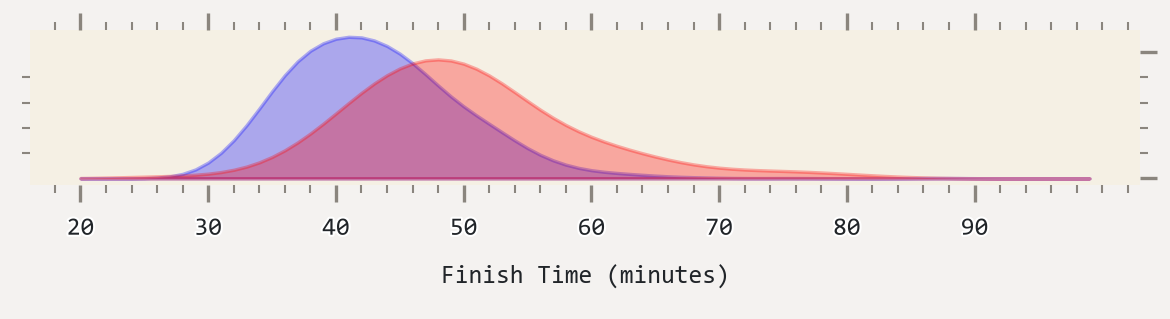

In [50]:
f, ax = plt.subplots(1,1, dpi=300, figsize=(4,1))
axis = range(20,100,1)

#ax.axvline(180)
#ax.axvline(240)
#ax.axvline(300)

ax.fill_between(axis, 100*GaussianKDE(men['Finish Time (seconds)']/60)(axis), alpha=0.3, color = 'blue')
ax.fill_between(axis, 100*GaussianKDE(women['Finish Time (seconds)']/60)(axis), alpha=0.3, color = 'red')
#ax.fill_between(axis, 100*GaussianKDE(nbinary['Chip Time (seconds)']/60)(axis), alpha=0.3, color = 'yellow')

#ax.plot(axis, 100*GaussianKDE(frames['Chip Time (seconds)']/60)(axis), color="black", linewidth=1, path_effects=[pe.Stroke(linewidth=1.5, foreground='w'), pe.Normal()])
    
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set(yticklabels=[])
ax.tick_params(left=False)
ax.grid(False)
f.tight_layout()

from math import ceil
axis = range(120,420,1)

#ax.axvline(180)
#ax.axvline(240)
#ax.axvline(300)

ax.set_xticks([20, 30, 40, 50, 60, 70, 80, 90])
ax.set_xticklabels([20, 30, 40, 50, 60, 70, 80, 90], 
               path_effects=[pe.Stroke(linewidth=1, foreground='w'), pe.Normal()],
               fontdict={"fontsize": 6, "fontfamily": "Consolas"},
               );

ax.set(yticklabels=[])
ax.tick_params(left=False)
ax.grid(False)
    
f.tight_layout()


ax.set_xlabel("Finish Time (minutes)", fontdict={"fontsize": 6, "fontfamily": "Consolas"},)

f.savefig("tinto-mens-womens-finish.png")

In [51]:
men

,RunnerPosition,Surname,Firstname,Club,RunnerCategory,FinishTime,FinishPosition,Finish Time (seconds)
0,1,Lennox,Jethro,Shettleston,S,30.50,NaN,1850
1,2,Anthony,Alasdair,Ochil,S,31.35,NaN,1895
2,3,Lenton,Tim,Lothian,S,32.41,NaN,1961
3,4,Marshall,Brain,HELP,S,32.54,NaN,1974
4,5,Ward,Adam,Carnethy,V,33.18,NaN,1998
...,...,...,...,...,...,...,...,...
175,176,Briggs,Andrew,Penicuik Harriers,M,0:55:09,NaN,3309
178,179,Howie,Frazer,Unattached,M,0:55:26,NaN,3326
179,180,Murray,Craig,Unattached,M,0:55:44,NaN,3344
200,201,Moss,Alastair,Unattached,M,1:00:21,NaN,3621


In [52]:
frames["RunnerCategory"].unique()

array(['S', 'V', 'FS', 'SV', 'SSV', 'SSSV', 'VS', 'FV', 'FJ', 'FSV',
       'FDS', nan, 'J', 'F', 'M', 'M40', 'M50', 'M60', 'F40', 'F50',
       'M70', 'F60', 'M80', 'v', 'f', 'v50', 'v60', 'fv', 'f50', 'fv50',
       'M ', 'Vet', 'S/Vet', 'Jnr', 'U 15', 'S/L', 'L/S', 'Over60',
       'L/Vet',
       'Due to the exceptionly bad weather the following were not recorded at the finish :',
       'MV', 'MJ', 'F70', 'MS', 'V50', 'V60', 'V40'], dtype=object)

In [53]:
def remap_categories(df, category_mapping):
    """
    Remap RunnerCategory values in a dataframe based on a mapping dictionary.
    
    Args:
        df: pandas DataFrame with a 'RunnerCategory' column
        category_mapping: dict mapping old category values to new ones
    
    Returns:
        Modified dataframe with categories remapped
    """
    for old_category, new_category in category_mapping.items():
        df.loc[df["RunnerCategory"] == old_category, "RunnerCategory"] = new_category
    return df

# Apply category remapping
category_remap = {"S": "M", "M ":"M", "MS": "M", "Over 60": "M60", "Over60": "M60", "MV": "M40", "v": "M40", "V": "M40", "SV": "M50", "S/Vet": "M50", "SSV": "M60", "SSSV": "M70", "V40": "M40", "V50": "M50", "V60": "M60", "V70": "M70",
                  "f": "F", "FS": "F", "fv": "F40", "fv50": "F50", "f50": "F50", "v60": "M60", "FV": "F40", "FSV": "F50", "FSSV": "F60", "FSSSV": "F70", "FV40": "F40", "FV50": "F50", "FV60": "F60", "FV70": "F70"}
frames = remap_categories(frames, category_remap)


In [54]:
frames["RunnerCategory"].unique()

array(['M', 'M40', 'F', 'M50', 'M60', 'M70', 'VS', 'F40', 'FJ', 'F50',
       'FDS', nan, 'J', 'F60', 'M80', 'v50', 'Vet', 'Jnr', 'U 15', 'S/L',
       'L/S', 'L/Vet',
       'Due to the exceptionly bad weather the following were not recorded at the finish :',
       'MJ', 'F70'], dtype=object)

/tmp/ipykernel_813647/3239483654.py:61: UserWarning: The figure layout has changed to tight
  f.tight_layout()


Text(0.5, 19.749999999999986, 'Finish Time (minutes)')

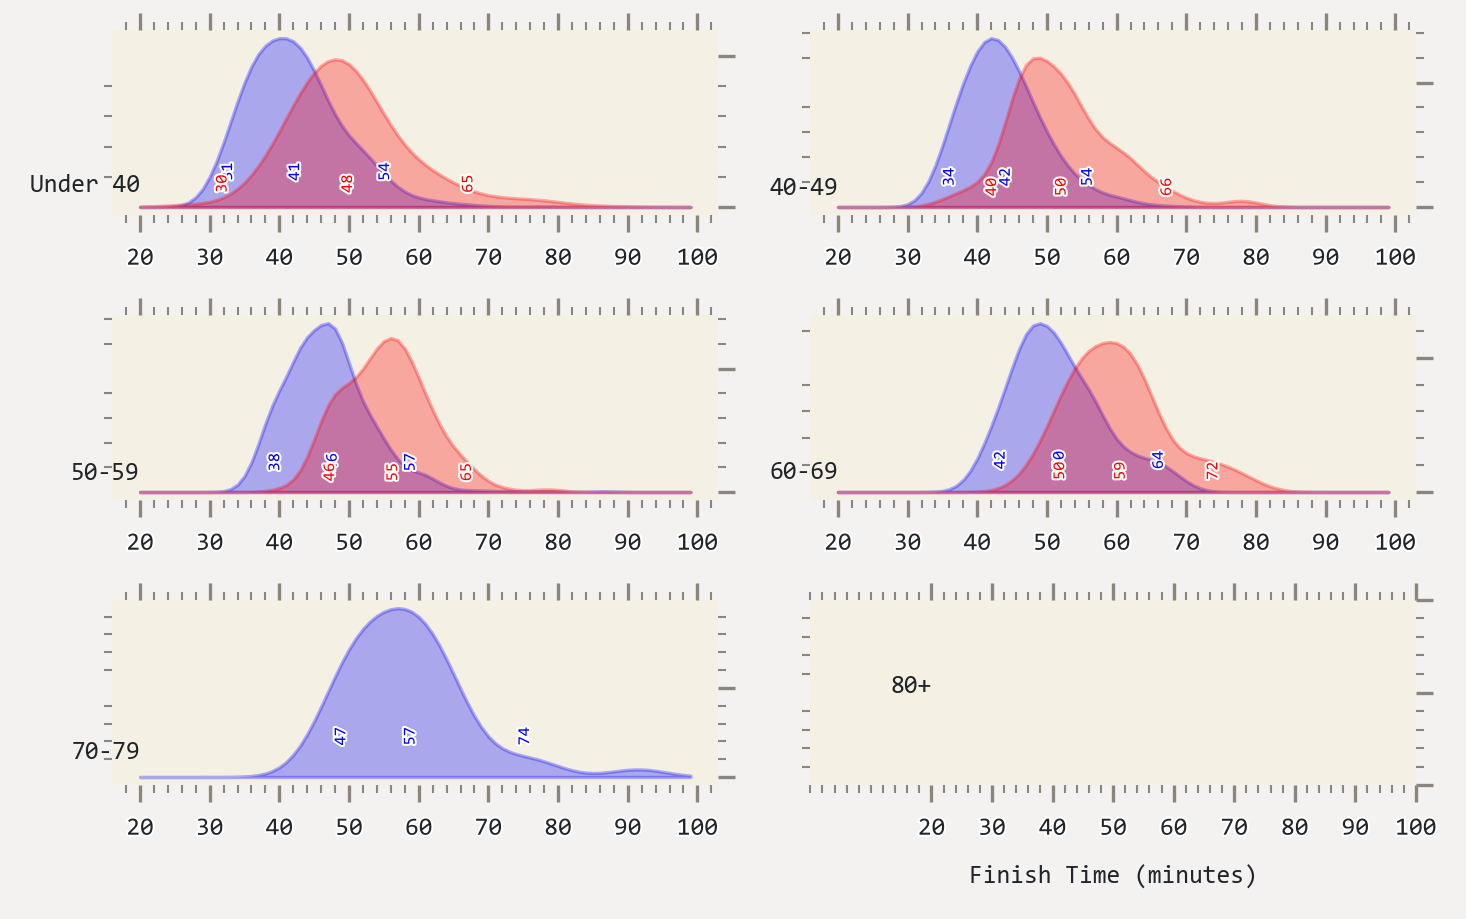

In [55]:
from math import ceil
axis = range(20,100,1)

categories = ("", "40", "50", "60", "70", "80")
category_labels = {
    "": "Under 40",
    "40": "40-49",
    "50": "50-59",
    "60": "60-69",
    "70": "70-79",
    "80": "80+",
}
f, axes = plt.subplots(ceil(len(categories)/2),2, dpi=300, figsize=(5,3), constrained_layout=True)
for category, ax in zip(categories, axes.flatten()):
    men = frames[frames['RunnerCategory']==(f"M{category}")]
    women = frames[frames['RunnerCategory']==(f"F{category}")]

    try:
        ax.fill_between(axis, 100*GaussianKDE(men['Finish Time (seconds)']/60)(axis), alpha=0.3, color = 'blue')
        for percentile in [0.05, 0.5, 0.95]:
            median = men['Finish Time (seconds)'].quantile(percentile)/60
            ax.text(median, 1.0, f"{int(median)}", ha="left", 
                    rotation=90,
                    path_effects=[pe.Stroke(linewidth=1, foreground='w'), pe.Normal()],
                    fontdict={"fontsize": 4, "fontfamily": "Consolas"}, color="blue")
    except:
        pass

    try:
        ax.fill_between(axis, 100*GaussianKDE(women['Finish Time (seconds)']/60)(axis), alpha=0.3, color = 'red')
        for percentile in [0.05, 0.5, 0.95]:
            median = women['Finish Time (seconds)'].quantile(percentile)/60
            ax.text(median, 0.6, f"{int(median)}", ha="left", 
                rotation=90,
                path_effects=[pe.Stroke(linewidth=1, foreground='w'), pe.Normal()],
                fontdict={"fontsize": 4, "fontfamily": "Consolas"}, color="red")
    except:
        pass

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    ax.text(20, 0.5, f"{category_labels[category]}", ha="right", fontdict={"fontsize": 6, "fontfamily": "Consolas"},)
    
    
        

    
    ax.set_xticks([20, 30, 40, 50, 60, 70, 80, 90, 100])
    ax.set_xticklabels([20, 30, 40, 50, 60, 70, 80, 90, 100], 
                   path_effects=[pe.Stroke(linewidth=1, foreground='w'), pe.Normal()],
                   fontdict={"fontsize": 6, "fontfamily": "Consolas"},
                   );
    
    ax.set(yticklabels=[])
    ax.tick_params(left=False)
    ax.grid(False)
    
f.tight_layout()

ax.set_xlabel("Finish Time (minutes)", fontdict={"fontsize": 6, "fontfamily": "Consolas"},)



#f.savefig("gsr-2022-finish-times.jpg")


In [56]:
import re

# Reload data with year extracted from filename, reapply all cleaning
data = []
for race_file in sorted(glob.glob("/home/daniel/repositories/personal/scottish-hillrunners-results/races/Tinto/*.csv")):
    year = int(re.search(r'(\d{4})\.csv$', race_file).group(1))
    df = pandas.read_csv(race_file)
    df['year'] = year
    data.append(df)

frames = pandas.concat(data, ignore_index=True)
frames['Finish Time (seconds)'] = frames['FinishTime'].map(str_to_seconds)

category_remap = {
    "S": "M", "M ": "M", "MS": "M", "MV": "M40",
    "v": "M40", "V": "M40", "SV": "M50", "S/Vet": "M50",
    "SSV": "M60", "SSSV": "M70", "V40": "M40", "V50": "M50",
    "V60": "M60", "V70": "M70", "v50": "M50", "v60": "M60",
    "VS": "M50", "Over60": "M60",
    "f": "F", "FS": "F", "FDS": "F",
    "fv": "F40", "FV": "F40", "FV40": "F40",
    "fv50": "F50", "f50": "F50", "FSV": "F50", "FV50": "F50",
    "FSSV": "F60", "FV60": "F60",
    "FSSSV": "F70", "FV70": "F70",
}
frames = remap_categories(frames, category_remap)

# Restrict to main categories with valid times
MAIN_CATEGORIES = ["M", "M40", "M50", "M60", "M70", "M80", "F", "F40", "F50", "F60", "F70"]
model_data = frames[
    frames['RunnerCategory'].isin(MAIN_CATEGORIES) &
    (frames['Finish Time (seconds)'] > 0) &
    frames['Finish Time (seconds)'].notna()
].copy()
model_data['log_time'] = np.log(model_data['Finish Time (seconds)'])

# Integer indices for model
cat_codes = pandas.Categorical(model_data['RunnerCategory'], categories=MAIN_CATEGORIES)
model_data['cat_idx'] = cat_codes.codes

year_levels = sorted(model_data['year'].unique())
year_to_idx = {y: i for i, y in enumerate(year_levels)}
model_data['year_idx'] = model_data['year'].map(year_to_idx)

# Standardised year for trend (zero-centred, unit variance)
year_arr = np.array(year_levels, dtype=float)
year_z = (year_arr - year_arr.mean()) / year_arr.std()

n_cats  = len(MAIN_CATEGORIES)
n_years = len(year_levels)

print(f"Categories : {MAIN_CATEGORIES}")
print(f"Years      : {year_levels[0]}–{year_levels[-1]}  ({n_years} years)")
print(f"Observations: {len(model_data)}")
print()
print(model_data.groupby('RunnerCategory', observed=True).size().reindex(MAIN_CATEGORIES).rename("count"))

Categories : ['M', 'M40', 'M50', 'M60', 'M70', 'M80', 'F', 'F40', 'F50', 'F60', 'F70']
Years      : 1985–2022  (37 years)
Observations: 5118

RunnerCategory
M      1150
M40    1521
M50     945
M60     285
M70      46
M80       1
F       592
F40     370
F50     167
F60      40
F70       1
Name: count, dtype: int64


In [57]:
import pymc as pm
import arviz as az

with pm.Model(coords={
    "category": MAIN_CATEGORIES,
    "year":     year_levels,
}) as tinto_model:

    # ── Data containers ──────────────────────────────────────────────────────
    cat_idx_data  = pm.Data("cat_idx",  model_data['cat_idx'].values)
    year_idx_data = pm.Data("year_idx", model_data['year_idx'].values)
    # year_z is a fixed lookup: year_z[year_idx] gives the standardised year
    year_z_data   = pm.Data("year_z",   year_z)   # one value per year level

    # ── Global hyperpriors ───────────────────────────────────────────────────
    # Prior centred on log(40 min) ≈ log(2400 s); the model works in log-seconds
    mu_global  = pm.Normal("mu_global",  mu=np.log(40 * 60), sigma=0.5)
    sigma_cat  = pm.HalfNormal("sigma_cat",  sigma=0.3)

    # ── Category means (partial pooling across categories) ───────────────────
    mu_category = pm.Normal("mu_category", mu=mu_global, sigma=sigma_cat,
                             dims="category")

    # ── Long-term secular trend ───────────────────────────────────────────────
    # In log-seconds per standardised year unit; negative = race getting faster
    trend = pm.Normal("trend", mu=0, sigma=0.1)

    # ── Year random effects (partial pooling) ────────────────────────────────
    # Non-centred parameterisation for better sampling
    sigma_year       = pm.HalfNormal("sigma_year", sigma=0.1)
    year_effect_raw  = pm.Normal("year_effect_raw", mu=0, sigma=1, dims="year")
    year_effect      = pm.Deterministic(
        "year_effect", year_effect_raw * sigma_year, dims="year")

    # ── Observation noise ─────────────────────────────────────────────────────
    sigma_obs = pm.HalfNormal("sigma_obs", sigma=0.15)

    # ── Linear predictor ─────────────────────────────────────────────────────
    mu_obs = (mu_category[cat_idx_data]
              + year_effect[year_idx_data]
              + trend * year_z_data[year_idx_data])

    # ── Likelihood ────────────────────────────────────────────────────────────
    log_time_obs = pm.Normal("log_time_obs", mu=mu_obs, sigma=sigma_obs,
                              observed=model_data['log_time'].values)

    # ── Derived quantities ────────────────────────────────────────────────────
    # Expected finish time in seconds per category (at trend midpoint, average year)
    pm.Deterministic("expected_time_s", pm.math.exp(mu_category), dims="category")

tinto_model

In [58]:
with tinto_model:
    trace = pm.sample(
        draws=2000,
        tune=1000,
        target_accept=0.9,
        random_seed=42,
        idata_kwargs={"log_likelihood": True},
    )
    pm.sample_posterior_predictive(trace, extend_inferencedata=True)

az.summary(trace, var_names=["mu_global", "sigma_cat", "trend", "sigma_year", "sigma_obs"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_global, sigma_cat, mu_category, trend, sigma_year, year_effect_raw, sigma_obs]


/home/daniel/projects/running-results/environment/lib/python3.13/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/daniel/projects/running-results/environment/lib/python3.13/site-packages/pymc/step_methods/hmc/quadpotential.py:316: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 12 seconds.
Sampling: [log_time_obs]


/home/daniel/projects/running-results/environment/lib/python3.13/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_global,8.014,0.048,7.925,8.104,0.001,0.001,4978.0,4549.0,1.00
sigma_cat,0.144,0.043,0.077,0.222,0.001,0.001,5489.0,4872.0,1.00
trend,0.026,0.008,0.010,0.041,0.000,0.000,1286.0,2335.0,1.01
sigma_year,0.047,0.011,0.027,0.067,0.000,0.000,900.0,1716.0,1.00
sigma_obs,0.135,0.001,0.132,0.137,0.000,0.000,7194.0,5641.0,1.00


/tmp/ipykernel_813647/2360801829.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


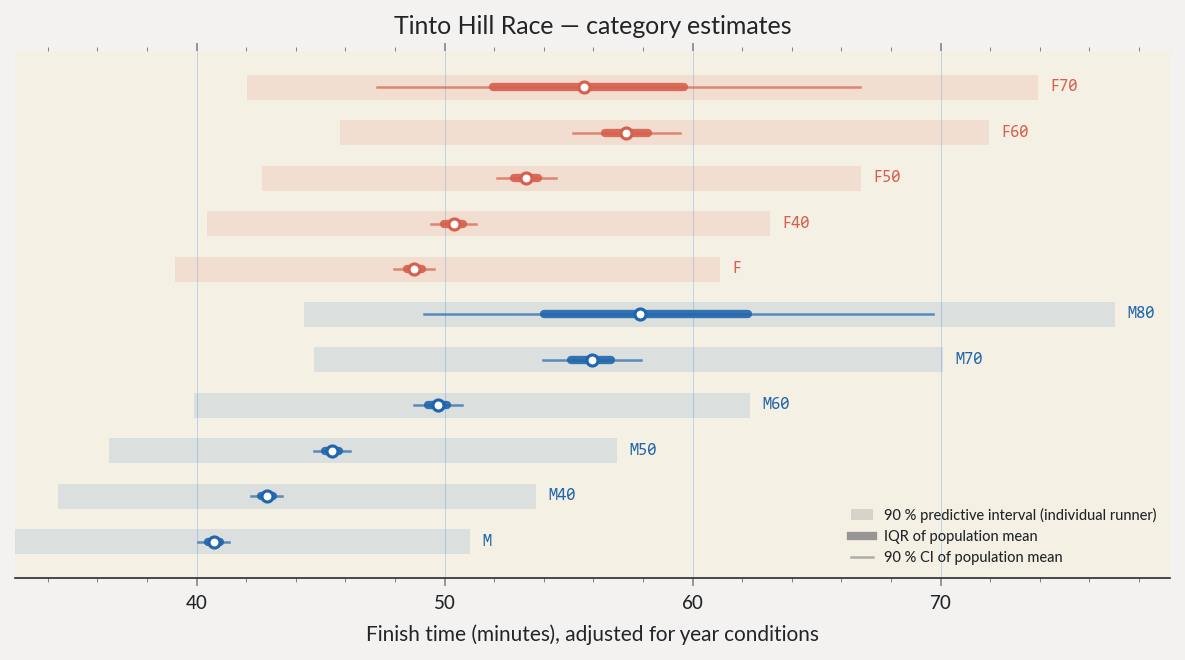

In [59]:
# ── Category posterior estimates ─────────────────────────────────────────────
# Two layers per category:
#   · Thin coloured line  = 90 % CI on the population mean (precision of the estimate)
#   · Wide grey band      = 90 % posterior predictive interval for an individual runner
#     (i.e. where 90 % of entrants in that cat, average year, would finish)
#
# The mean CI is tight for M/M40 (1000+ obs) and wide for M80/F70 (1 obs each),
# where partial pooling pulls the estimate toward the global mean.

rng = np.random.default_rng(0)

mu_cat_draws  = trace.posterior["mu_category"].values   # (chain, draw, n_cats)
sigma_draws   = trace.posterior["sigma_obs"].values     # (chain, draw)

n_chains, n_draws, _ = mu_cat_draws.shape
mu_flat   = mu_cat_draws.reshape(-1, n_cats)            # (S, n_cats)
sig_flat  = sigma_draws.ravel()                         # (S,)

# Predictive samples: for each posterior draw, one N(0,1) perturbation
z = rng.standard_normal(len(sig_flat))
pred_log = mu_flat + (sig_flat * z)[:, None]            # (S, n_cats)
pred_min  = np.exp(pred_log) / 60

# Mean CI samples
mean_min  = np.exp(mu_flat) / 60

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

for i, cat in enumerate(MAIN_CATEGORIES):
    color = "#2166ac" if cat.startswith("M") else "#d6604d"

    # Predictive interval (90 %) — wide, shown as a faint filled bar
    p05, p95 = np.quantile(pred_min[:, i], [0.05, 0.95])
    ax.barh(i, p95 - p05, left=p05, height=0.55,
            color=color, alpha=0.12, linewidth=0)

    # Mean CI (90 %) — thin line
    m05, m25, m50, m75, m95 = np.quantile(mean_min[:, i], [0.05, 0.25, 0.5, 0.75, 0.95])
    ax.plot([m05, m95], [i, i], color=color, linewidth=1.2, alpha=0.7)
    ax.plot([m25, m75], [i, i], color=color, linewidth=4, alpha=0.9,
            solid_capstyle="round")
    ax.scatter([m50], [i], color="white", edgecolors=color, s=28, zorder=5, linewidths=1.5)

    ax.text(p95 + 0.5, i, cat, va="center", fontsize=8, color=color,
            fontfamily="Consolas")

# Legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Patch(facecolor="grey", alpha=0.25, label="90 % predictive interval (individual runner)"),
    Line2D([0], [0], color="grey", linewidth=4, alpha=0.8, label="IQR of population mean"),
    Line2D([0], [0], color="grey", linewidth=1.2, alpha=0.6, label="90 % CI of population mean"),
]
ax.legend(handles=legend_elements, fontsize=7, loc="lower right", frameon=False)

ax.set_yticks([])
ax.set_xlabel("Finish time (minutes), adjusted for year conditions")
ax.set_title("Tinto Hill Race — category estimates")
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()

/tmp/ipykernel_813647/639491256.py:28: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


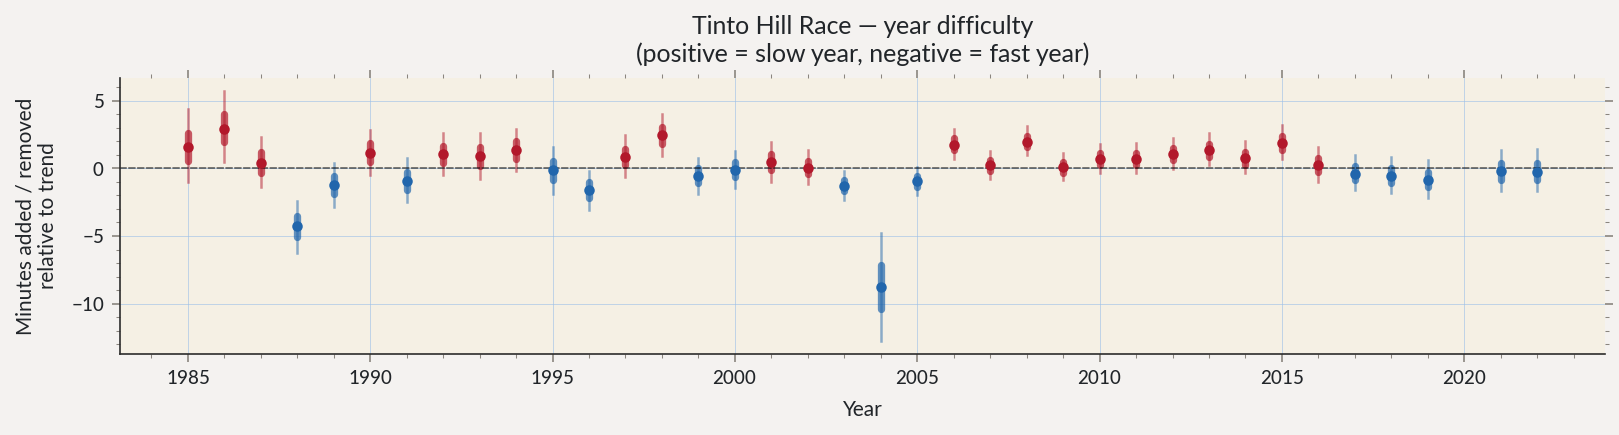

In [60]:
# ── Year difficulty ───────────────────────────────────────────────────────────
# Convert year_effect (log-seconds) to minutes relative to a typical finish.
# Δt ≈ exp(effect) - 1 expressed as a fraction of the median expected time.
median_time_s = float(np.exp(trace.posterior["mu_global"].values.mean()))
year_fx = trace.posterior["year_effect"].values   # (chain, draw, year)

fig, ax = plt.subplots(figsize=(11, 3), dpi=150)

for i, yr in enumerate(year_levels):
    vals = year_fx[:, :, i].ravel()
    q05, q25, q50, q75, q95 = np.quantile(vals, [0.05, 0.25, 0.5, 0.75, 0.95])

    # Convert log-second effects to additive minutes
    def to_min(log_effect):
        return (np.exp(log_effect) - 1) * median_time_s / 60

    color = "#b2182b" if q50 > 0 else "#2166ac"
    ax.plot([yr, yr], [to_min(q05), to_min(q95)], color=color, linewidth=1.2, alpha=0.5)
    ax.plot([yr, yr], [to_min(q25), to_min(q75)], color=color, linewidth=3.5, alpha=0.7,
            solid_capstyle="round")
    ax.scatter([yr], [to_min(q50)], color=color, s=18, zorder=5)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
ax.set_xlabel("Year")
ax.set_ylabel("Minutes added / removed\nrelative to trend")
ax.set_title("Tinto Hill Race — year difficulty\n(positive = slow year, negative = fast year)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

/tmp/ipykernel_813647/670619535.py:48: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


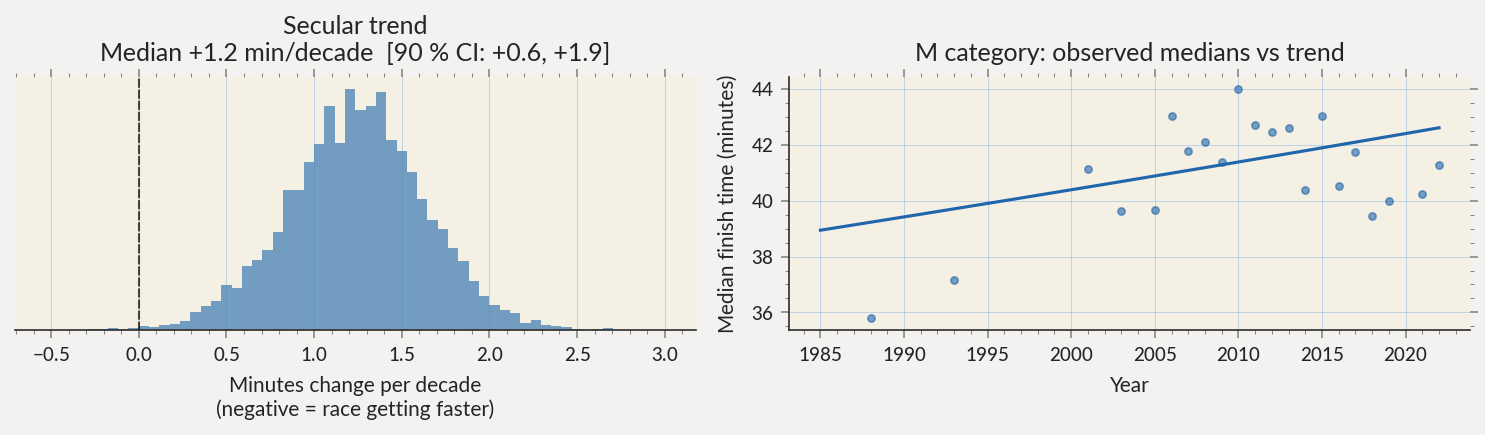

In [61]:
# ── Long-term secular trend ───────────────────────────────────────────────────
# trend is in log-seconds per standardised-year unit.
# Convert to "minutes per decade" for a typical category finish time.
trend_samples = trace.posterior["trend"].values.ravel()

std_per_decade = 10.0 / year_arr.std()                    # std units in 10 calendar years
# Multiplicative change per decade: exp(trend * std_per_decade)
# Additive change in minutes: (mult - 1) * median_time_s / 60
trend_min_per_decade = (np.exp(trend_samples * std_per_decade) - 1) * median_time_s / 60

fig, axes = plt.subplots(1, 2, figsize=(10, 3), dpi=150)

# Left: posterior of trend in min/decade
ax = axes[0]
ax.hist(trend_min_per_decade, bins=60, color="steelblue", alpha=0.75, edgecolor="none")
ax.axvline(0, color="black", linewidth=1, linestyle="--", alpha=0.7)
q05, q50, q95 = np.quantile(trend_min_per_decade, [0.05, 0.5, 0.95])
ax.set_xlabel("Minutes change per decade\n(negative = race getting faster)")
ax.set_title(f"Secular trend\nMedian {q50:+.1f} min/decade  [90 % CI: {q05:+.1f}, {q95:+.1f}]")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([])

# Right: trend overlaid on year-specific expected fastest times (M category)
m_idx = MAIN_CATEGORIES.index("M")
ax = axes[1]
trend_mean   = float(trace.posterior["trend"].values.mean())
mu_cat_mean  = trace.posterior["mu_category"].values.mean(axis=(0, 1))   # (n_cats,)
year_fx_mean = trace.posterior["year_effect"].values.mean(axis=(0, 1))   # (n_years,)

# Observed year medians for M category
for i, yr in enumerate(year_levels):
    mask = (model_data['year_idx'] == i) & (model_data['cat_idx'] == m_idx)
    if mask.sum() > 0:
        med_s = model_data.loc[mask, 'Finish Time (seconds)'].median()
        ax.scatter(yr, med_s / 60, color="#2166ac", s=12, alpha=0.6, zorder=3)

# Trend line (no year noise, just secular trend + category mean)
yr_plot = np.linspace(year_arr.min(), year_arr.max(), 200)
yr_z_plot = (yr_plot - year_arr.mean()) / year_arr.std()
trend_line = np.exp(mu_cat_mean[m_idx] + trend_mean * yr_z_plot) / 60
ax.plot(yr_plot, trend_line, color="#2166ac", linewidth=1.5, label="Trend (M)")

ax.set_xlabel("Year")
ax.set_ylabel("Median finish time (minutes)")
ax.set_title("M category: observed medians vs trend")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

In [62]:
# ── Outstanding performances ──────────────────────────────────────────────────
# Score each result as a standardised residual from its (category × year) expectation.
# z < 0 → faster than expected; large |z| → exceptional.

sigma_obs_mean = float(trace.posterior["sigma_obs"].values.mean())

scored = model_data.copy()
scored['expected_log_time'] = (
    mu_cat_mean[scored['cat_idx'].values]
    + year_fx_mean[scored['year_idx'].values]
    + trend_mean * year_z[scored['year_idx'].values]
)
scored['residual_z'] = (scored['log_time'] - scored['expected_log_time']) / sigma_obs_mean
# Positive z = slower than expected; negative z = faster
scored['pct_from_expected'] = (np.exp(scored['residual_z'] * sigma_obs_mean) - 1) * 100

cols = ['year', 'Firstname', 'Surname', 'Club', 'RunnerCategory', 'FinishTime', 'residual_z', 'pct_from_expected']

print("═" * 70)
print("TOP 15 OUTSTANDING PERFORMANCES  (fastest relative to category × year)")
print("═" * 70)
top = scored.nsmallest(15, 'residual_z')[cols].reset_index(drop=True)
top.index += 1
print(top.to_string())

print()
print("═" * 70)
print("SLOWEST 10 RELATIVE PERFORMANCES")
print("═" * 70)
bot = scored[scored['Finish Time (seconds)'] < scored['Finish Time (seconds)'].quantile(0.95)]\
      .nlargest(10, 'residual_z')[cols].reset_index(drop=True)
bot.index += 1
print(bot.to_string())

══════════════════════════════════════════════════════════════════════
TOP 15 OUTSTANDING PERFORMANCES  (fastest relative to category × year)
══════════════════════════════════════════════════════════════════════
    year  Firstname      Surname         Club RunnerCategory FinishTime  residual_z  pct_from_expected
1   2004     Martha       Aitken     Carnethy              F      25.26   -3.420927         -36.904996
2   2004    Deborah       Stokoe  Westerlands              F      26.11   -3.205044         -35.044396
3   2004       Evie       Aitken     Carnethy              F      27.07   -2.944866         -32.728983
4   2012     Angela        Mudge     Carnethy            F40    0:35:47   -2.853201         -31.893722
5   2010     Angela        Mudge     Carnethy            F40    0:35:38   -2.797740         -31.383319
6   2007     Angela        Mudge     Carnethy              F    0:34:29   -2.681002         -30.296459
7   2008     Angela        Mudge     Carnethy              F    0:

In [63]:
# ── Club normalisation ────────────────────────────────────────────────────────
CLUB_ALIASES = {
    # Carnethy
    "Carnethy Hill Running Club": "Carnethy",
    # Ochil
    "Ochil": "Ochil Hill Runners",
    "Ochils": "Ochil Hill Runners",
    "Ochil HR": "Ochil Hill Runners",
    # Lomond
    "Lomond": "Lomond Hill Runners",
    "Lomonds": "Lomond Hill Runners",
    # Shettleston
    "Shettleston": "Shettleston Harriers",
    # Fife
    "Fife": "Fife AC",
    "FIfe": "Fife AC",
    # Carnegie
    "Carnegie": "Carnegie Harriers",
    "EZ Carnegie": "Carnegie Harriers",
    "E Z Carnegie": "Carnegie Harriers",
    # Hunters Bog Trotters
    "HBT": "Hunters Bog Trotters",
    # Unattached
    "U/A": "Unattached",
    "U/a": "Unattached",
    # Lomond school is not the running club
}

def normalise_club(name):
    if pandas.isna(name):
        return "Unattached"
    name = str(name).strip()
    return CLUB_ALIASES.get(name, name)

model_data["club"] = frames.loc[model_data.index, "Club"].map(normalise_club)

# Attach year-adjusted time: remove the year random effect so clubs are comparable
# across different editions.  Use posterior mean year effects computed above.
mu_cat_draws_cl = trace.posterior["mu_category"].values
year_fx_draws_cl = trace.posterior["year_effect"].values
mu_cat_mean_cl  = mu_cat_draws_cl.mean(axis=(0, 1))
year_fx_mean_cl = year_fx_draws_cl.mean(axis=(0, 1))
trend_mean_cl   = float(trace.posterior["trend"].values.mean())

model_data["adjusted_log_time"] = (
    model_data["log_time"]
    - year_fx_mean_cl[model_data["year_idx"].values]
    - trend_mean_cl * year_z[model_data["year_idx"].values]
)
model_data["adjusted_time_min"] = np.exp(model_data["adjusted_log_time"]) / 60

# ── Top clubs by entry count ──────────────────────────────────────────────────
MIN_ENTRIES = 30
club_stats = (
    model_data
    .groupby("club")["adjusted_time_min"]
    .agg(entries="count", median="median", q25=lambda x: x.quantile(0.25),
         q75=lambda x: x.quantile(0.75))
    .query("entries >= @MIN_ENTRIES")
    .sort_values("entries", ascending=False)
)
print(f"Clubs with ≥{MIN_ENTRIES} entries:")
print(club_stats.head(20).to_string())

Clubs with ≥30 entries:
                      entries     median        q25        q75
club                                                          
Carnethy                  871  43.395819  39.062814  48.796388
Unattached                597  48.037465  43.475879  52.954505
Westerlands               301  43.956217  40.226173  48.352454
Carnegie Harriers         205  47.030735  41.879763  52.251409
Ochil Hill Runners        203  42.258407  37.908789  45.737823
Lomond Hill Runners       149  45.064338  42.725239  48.382155
Penicuik Harriers         136  47.591082  41.606638  51.156327
Shettleston Harriers      133  37.068391  34.200050  41.444453
Hunters Bog Trotters      131  43.554446  38.671811  48.350742
Fife AC                   107  42.623381  39.854632  46.581754
Tinto Hill Runners         88  47.782537  44.130208  50.707999
Bellahouston RR            86  43.540360  39.181767  49.032014
Hartfell HRC               83  40.640310  38.425326  50.427690
Solway                     68  

/tmp/ipykernel_813647/1047115492.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


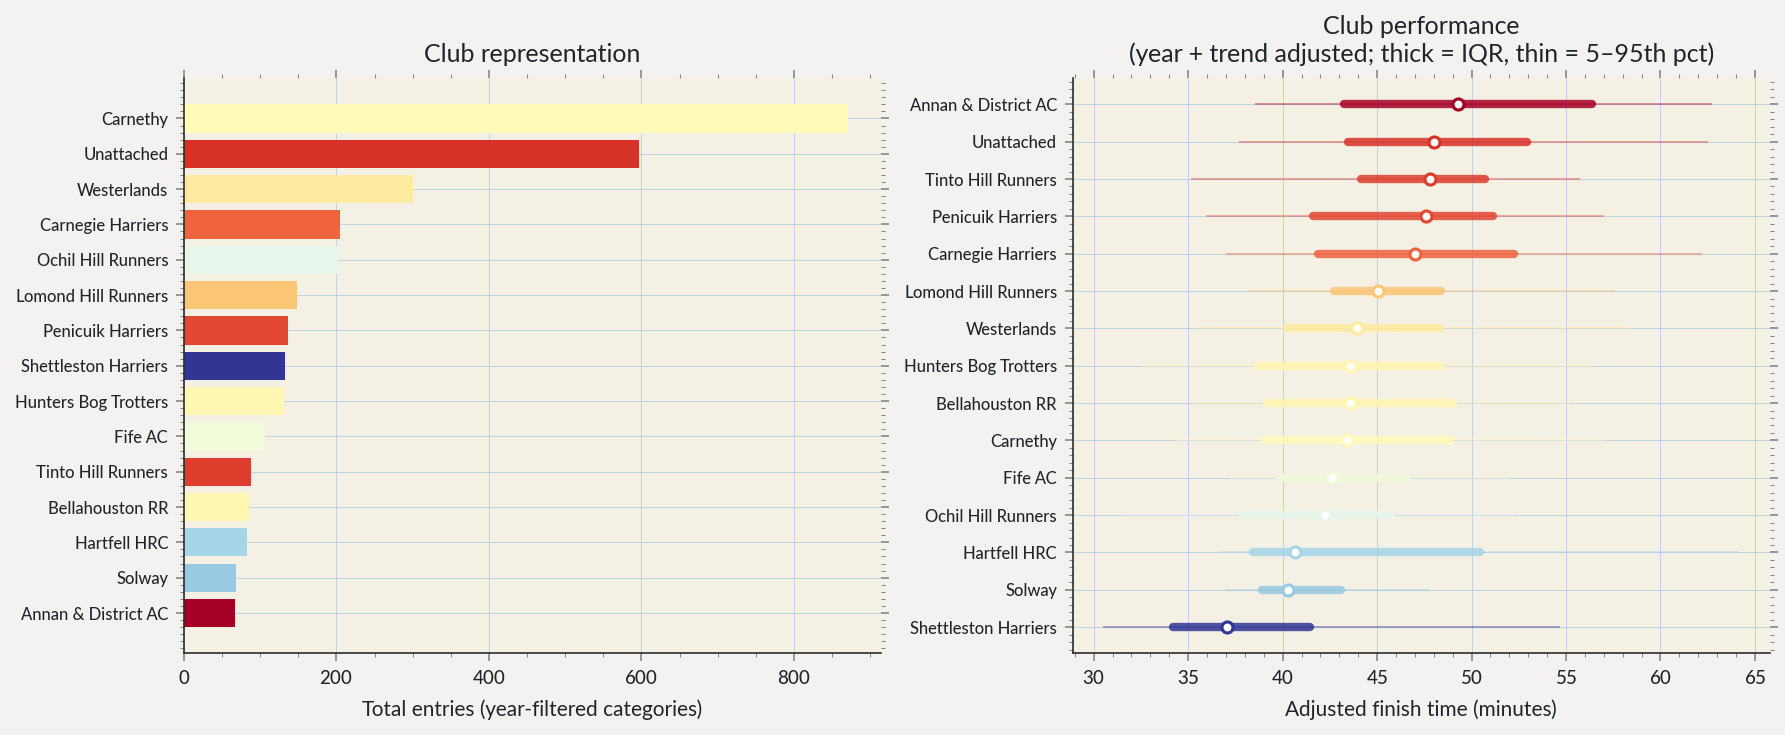

In [64]:
# ── Club visualisation ────────────────────────────────────────────────────────
# Two panels:
#   Left  — entries per club (top 15 by count), coloured by median adjusted time
#   Right — IQR of adjusted finish time per club (top 15 by count), sorted by median

TOP_N = 15
top_clubs = club_stats.head(TOP_N).index.tolist()
top_df    = club_stats.loc[top_clubs].copy()

# Colour by median time (faster = darker blue)
norm   = plt.Normalize(top_df["median"].min(), top_df["median"].max())
cmap   = plt.cm.RdYlBu_r
colors = [cmap(norm(v)) for v in top_df["median"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

# Left: entries bar chart
ax = axes[0]
ax.barh(range(TOP_N), top_df["entries"], color=colors, edgecolor="none")
ax.set_yticks(range(TOP_N))
ax.set_yticklabels(top_clubs, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Total entries (year-filtered categories)")
ax.set_title("Club representation")
ax.spines[["top", "right"]].set_visible(False)

# Right: IQR plot sorted by median (fastest at top)
ax = axes[1]
sorted_clubs = top_df.sort_values("median").index.tolist()
sorted_df    = top_df.loc[sorted_clubs]
sorted_colors = [cmap(norm(v)) for v in sorted_df["median"]]

for rank, (club, row) in enumerate(sorted_df.iterrows()):
    c = sorted_colors[rank]
    # Full range visible in data
    club_times = model_data.loc[model_data["club"] == club, "adjusted_time_min"]
    p05, p95 = club_times.quantile([0.05, 0.95])
    ax.plot([p05, p95], [rank, rank], color=c, linewidth=1, alpha=0.4)
    ax.plot([row.q25, row.q75], [rank, rank], color=c, linewidth=4,
            solid_capstyle="round", alpha=0.85)
    ax.scatter([row["median"]], [rank], color="white", edgecolors=c,
               s=28, zorder=5, linewidths=1.5)

ax.set_yticks(range(len(sorted_clubs)))
ax.set_yticklabels(sorted_clubs, fontsize=8)
ax.set_xlabel("Adjusted finish time (minutes)")
ax.set_title("Club performance\n(year + trend adjusted; thick = IQR, thin = 5–95th pct)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

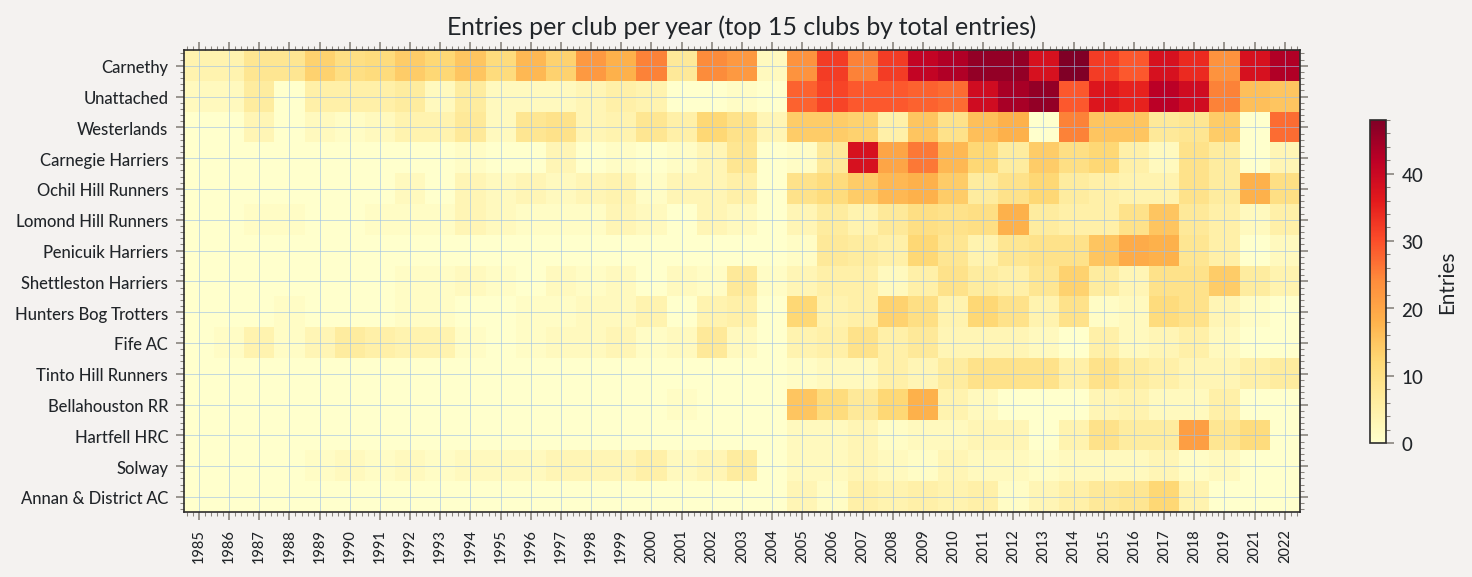

In [65]:
# ── Club entries over time ────────────────────────────────────────────────────
# For each year, how many runners did each top club send?
# Show as a stacked area / heatmap to reveal which clubs have grown or faded.

pivot = (
    model_data[model_data["club"].isin(top_clubs)]
    .groupby(["year", "club"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=top_clubs)   # keep entry-count order
)

fig, ax = plt.subplots(figsize=(12, 4), dpi=150)

im = ax.imshow(
    pivot.T.values,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest",
)
ax.set_xticks(range(len(pivot.index)))
ax.set_xticklabels(pivot.index, rotation=90, fontsize=7)
ax.set_yticks(range(len(top_clubs)))
ax.set_yticklabels(top_clubs, fontsize=8)
ax.set_title("Entries per club per year (top 15 clubs by total entries)")

plt.colorbar(im, ax=ax, label="Entries", shrink=0.7)
plt.tight_layout()

In [66]:
# ── Course-specific age-grading ───────────────────────────────────────────────
# Age-grading converts every result to a "M-open equivalent" time, enabling
# fair comparison across categories.
#
# Standard WMA tables use fixed road-running world records which don't apply here.
# Instead we derive factors directly from the model:
#
#   factor[cat] = exp(mu_category[M] - mu_category[cat])
#
# This is the posterior estimate of how much faster a typical M runner is than
# a typical runner in category `cat`, calibrated to this course and field.
# factor[M] = 1.0 by construction.
#
# age-graded time = actual_time × factor[cat]
# age-graded %    = (posterior median M time) / age-graded time × 100
#
# A score of 100% means you ran as fast as the typical M-open Tinto runner.
# A score > 100% means you beat that benchmark.

# ── Posterior distribution of factors ────────────────────────────────────────
mu_cat_post = trace.posterior["mu_category"].values   # (chain, draw, n_cats)
S = mu_cat_post.shape[0] * mu_cat_post.shape[1]
mu_flat_ag  = mu_cat_post.reshape(S, n_cats)

m_open_idx = MAIN_CATEGORIES.index("M")
# factor draws: shape (S, n_cats)
factor_draws = np.exp(mu_flat_ag[:, m_open_idx, None] - mu_flat_ag)  # ≤ 1 for slower cats

factor_median = np.median(factor_draws, axis=0)
factor_q05    = np.quantile(factor_draws, 0.05, axis=0)
factor_q95    = np.quantile(factor_draws, 0.95, axis=0)

print("Course-specific age-grading factors (M-open = 1.00)")
print(f"{'Category':<8}  {'Factor (median)':>16}  {'90% CI':>18}")
for i, cat in enumerate(MAIN_CATEGORIES):
    print(f"  {cat:<6}  {factor_median[i]:>16.4f}  [{factor_q05[i]:.4f}, {factor_q95[i]:.4f}]")

Course-specific age-grading factors (M-open = 1.00)
Category   Factor (median)              90% CI
  M                 1.0000  [1.0000, 1.0000]
  M40               0.9498  [0.9413, 0.9583]
  M50               0.8950  [0.8863, 0.9038]
  M60               0.8185  [0.8068, 0.8305]
  M70               0.7278  [0.7040, 0.7517]
  M80               0.7033  [0.5837, 0.8268]
  F                 0.8342  [0.8247, 0.8439]
  F40               0.8080  [0.7972, 0.8190]
  F50               0.7637  [0.7496, 0.7779]
  F60               0.7099  [0.6857, 0.7355]
  F70               0.7316  [0.6087, 0.8602]


In [67]:
# ── Apply age-grading to every result ────────────────────────────────────────
m_median_s = float(np.exp(mu_flat_ag[:, m_open_idx].mean()))

scored["ag_factor"]   = factor_median[scored["cat_idx"].values]
scored["ag_time_min"] = scored["Finish Time (seconds)"] / 60 * scored["ag_factor"]
scored["ag_score"]    = m_median_s / 60 / scored["ag_time_min"] * 100

# ── All-time leaderboard ──────────────────────────────────────────────────────
ag_cols = ["year", "Firstname", "Surname", "Club", "RunnerCategory",
           "FinishTime", "ag_time_min", "ag_score"]

print("ALL-TIME TOP 20 BY AGE-GRADED SCORE")
print("(100 % = typical M-open Tinto performance, >100 % = exceptional)")
print("═" * 75)
top_ag = scored.nlargest(20, "ag_score")[ag_cols].reset_index(drop=True)
top_ag.index += 1
top_ag["ag_time_min"] = top_ag["ag_time_min"].map(lambda x: f"{int(x)}:{int((x%1)*60):02d}")
top_ag["ag_score"]    = top_ag["ag_score"].map(lambda x: f"{x:.1f}%")
print(top_ag.to_string())

print()
print("TOP 5 PER CATEGORY")
print("═" * 75)
for cat in MAIN_CATEGORIES:
    sub = scored[scored["RunnerCategory"] == cat].nlargest(5, "ag_score")
    if len(sub) == 0:
        continue
    print(f"\n{cat}:")
    print(sub[ag_cols].assign(
        ag_time_min=lambda d: d["ag_time_min"].map(lambda x: f"{int(x)}:{int((x%1)*60):02d}"),
        ag_score=lambda d: d["ag_score"].map(lambda x: f"{x:.1f}%"),
    ).reset_index(drop=True).to_string())

ALL-TIME TOP 20 BY AGE-GRADED SCORE
(100 % = typical M-open Tinto performance, >100 % = exceptional)
═══════════════════════════════════════════════════════════════════════════
    year  Firstname      Surname         Club RunnerCategory FinishTime ag_time_min ag_score
1   2004     Martha       Aitken     Carnethy              F      25.26       21:13   191.8%
2   2004    Deborah       Stokoe  Westerlands              F      26.11       21:50   186.3%
3   2004       Evie       Aitken     Carnethy              F      27.07       22:37   179.9%
4   2004      Laura     Paterson  Shettleston              F      30.38       25:33   159.2%
5   2004     Rachel       Robson        Annan              F      30.43       25:37   158.8%
6   2007     Angela        Mudge     Carnethy              F    0:34:29       28:46   141.4%
7   2010     Angela        Mudge     Carnethy            F40    0:35:38       28:47   141.3%
8   2012     Angela        Mudge     Carnethy            F40    0:35:47       2

/tmp/ipykernel_813647/2593761582.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


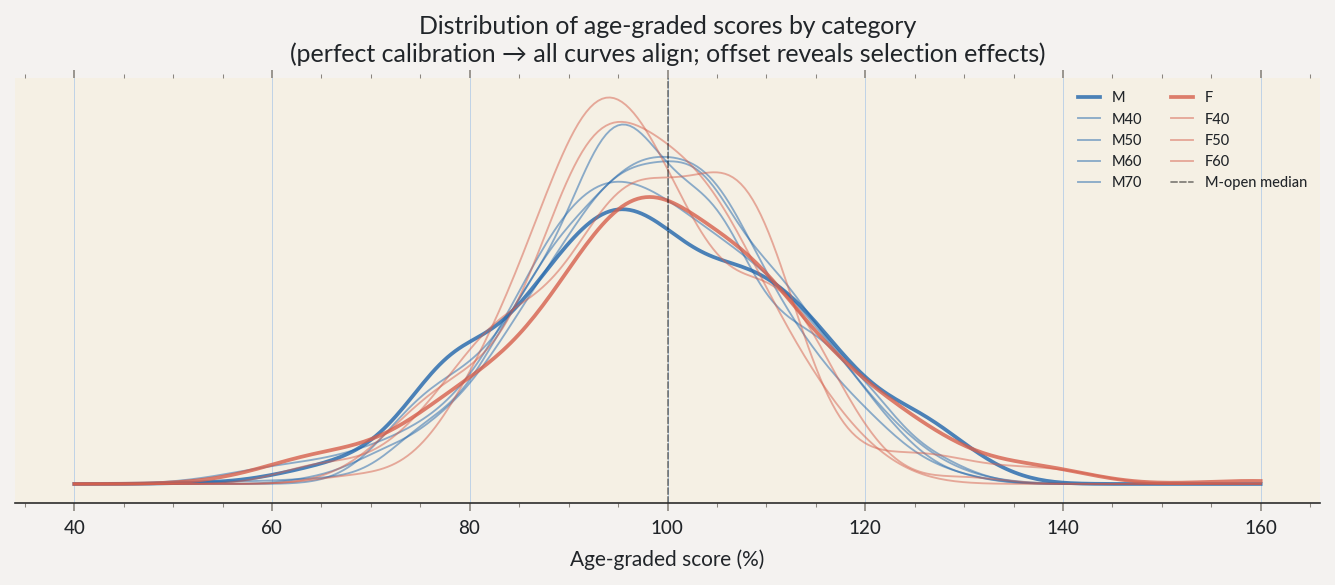

In [68]:
# ── Age-graded score distributions ───────────────────────────────────────────
# After grading, categories should have similar distributions if the factors
# are well-calibrated. Deviations reveal where the field is especially
# competitive or where small sample sizes make the estimate uncertain.

fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
axis_range = np.linspace(40, 160, 300)

for i, cat in enumerate(MAIN_CATEGORIES):
    sub = scored.loc[scored["RunnerCategory"] == cat, "ag_score"]
    if len(sub) < 5:
        continue
    color = "#2166ac" if cat.startswith("M") else "#d6604d"
    lw = 1.8 if cat in ("M", "F") else 0.9
    alpha = 0.8 if cat in ("M", "F") else 0.5
    try:
        kde = GaussianKDE(sub)(axis_range)
        ax.plot(axis_range, kde, color=color, linewidth=lw, alpha=alpha, label=cat)
    except Exception:
        pass

ax.axvline(100, color="black", linewidth=0.8, linestyle="--", alpha=0.5, label="M-open median")
ax.legend(ncol=2, fontsize=7, frameon=False)
ax.set_xlabel("Age-graded score (%)")
ax.set_title("Distribution of age-graded scores by category\n"
             "(perfect calibration → all curves align; offset reveals selection effects)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([])
plt.tight_layout()